In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.chdir("/content/drive/MyDrive/Vehicle-type-classification")

Mounted at /content/drive


In [4]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 33.0 MB/s eta 0:00:00


In [5]:
import cv2
import matplotlib.pyplot as plt

from src.detector import VehicleDetector

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [6]:
detector = VehicleDetector(
    model_path="yolov8n.pt",
    conf=0.4
)

In [7]:
video_path = "data/test-video/1900-151662242_medium.mp4"
cap = cv2.VideoCapture(video_path)
ret, frame = cap.read()
cap.release()

print(frame.shape)

(720, 1280, 3)


In [8]:
detections = detector.detect(frame)
print("Vehicles found:", len(detections))

Vehicles found: 9


In [9]:
for d in detections:
    print(d)

{'box': (554, 567, 816, 716), 'confidence': 0.865178108215332, 'class_name': 'car'}
{'box': (520, 368, 712, 527), 'confidence': 0.8644940257072449, 'class_name': 'car'}
{'box': (802, 301, 997, 450), 'confidence': 0.8524125218391418, 'class_name': 'car'}
{'box': (420, 264, 583, 394), 'confidence': 0.805837094783783, 'class_name': 'car'}
{'box': (600, 191, 738, 309), 'confidence': 0.7562978267669678, 'class_name': 'bus'}
{'box': (192, 194, 266, 241), 'confidence': 0.7204431295394897, 'class_name': 'car'}
{'box': (391, 225, 514, 343), 'confidence': 0.5767703652381897, 'class_name': 'car'}
{'box': (325, 186, 443, 298), 'confidence': 0.46009960770606995, 'class_name': 'truck'}
{'box': (326, 186, 444, 296), 'confidence': 0.40025773644447327, 'class_name': 'car'}


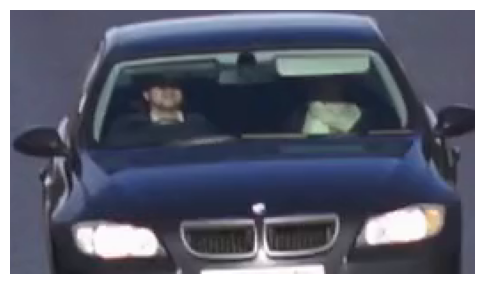

In [10]:
x1, y1, x2, y2 = detections[0]["box"]
crop = frame[y1:y2, x1:x2]

plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [11]:
os.makedirs("outputs/crops", exist_ok=True)

In [13]:
for i, d in enumerate(detections):
  x1, y1, x2, y2 = d["box"]
  crop = frame[y1:y2, x1:x2]
  cv2.imwrite(f"outputs/crops/vehicle_{i}.jpg", crop)